In [1]:
print("hello world")

hello world


### Convolution

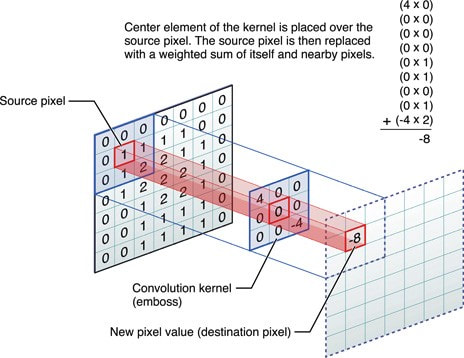

In [2]:
from PIL import Image
img = Image.open("convolution.jpeg")
img

In [20]:
# Implementing simple convolution
import numpy as np
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

img = Image.open("ishowspeed.webp").convert("L")
transform = transforms.ToTensor()

img_tensor = transform(img)
print('Shape after transform', img_tensor.shape)

kernel_matrix = [
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
]
constant = 16
blur_kernel = [
    [1/constant, 2/constant, 1/constant],
    [2/constant, 4/constant, 2/constant],
    [1/constant, 2/constant, 1/constant]
]
custom_kernel = torch.tensor(kernel_matrix, dtype=torch.float32)
custom_kernel = custom_kernel.view(1, 1, 3, 3)

# adding batch dimension at the beginning
# img_tensor = img_tensor.unsqueeze(0)
print(" Shape with batch dimension", img_tensor.shape)

conv_layer = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, stride=1, padding=1, bias=False)

conv_layer.weight = nn.Parameter(custom_kernel)

# conv_layer.weight.requires_grad = False

with torch.no_grad():
    output_tensor = conv_layer(img_tensor)

print("Output shape: ", output_tensor.shape)

Shape after transform torch.Size([1, 720, 1280])
 Shape with batch dimension torch.Size([1, 720, 1280])
Output shape:  torch.Size([1, 720, 1280])


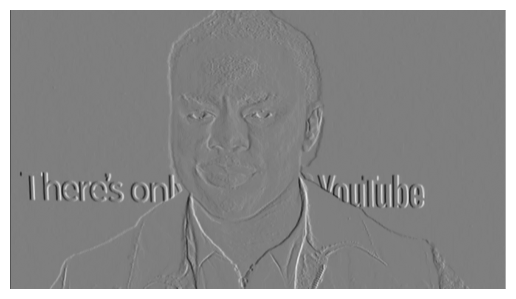

In [21]:
feature_map = output_tensor.squeeze().numpy()

# Display the feature map as a grayscale image
plt.imshow(feature_map, cmap="gray")
plt.axis("off")
plt.show()

## LENET FOR MNIST

In [22]:
from torchvision import datasets

train_dataset = datasets.MNIST(root="./datasets", train=True, download=True)
test_dataset = datasets.MNIST(root="./datasets", train=False, download=True)

100%|██████████| 9.91M/9.91M [00:08<00:00, 1.21MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 97.0kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 992kB/s] 
100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]


In [40]:
class_names = train_dataset.classes
print("Classes: ", class_names)
print("Total number of images in training dataset : ", len(train_dataset))
print("Total number of images in testing dataset : ", len(test_dataset))

Classes:  ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
Total number of images in training dataset :  60000
Total number of images in testing dataset :  10000


In [38]:
img, label = train_dataset[59999]
img, label

(<PIL.Image.Image image mode=L size=28x28>, 8)

Text(0.5, 1.0, '3 - three')

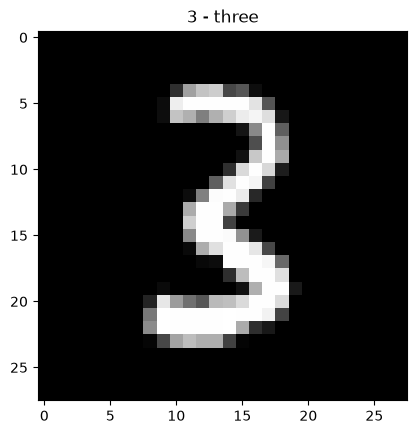

In [34]:
import matplotlib.pyplot as plt

plt.imshow(img, cmap="gray")
plt.title(f"{class_names[label]}")

In [62]:
# Image visualization
import numpy as np
def img_pixel_superimpose(img, ax):
    w, h = img.shape
    color_map = plt.colormaps['gray_r']  # gray_reversed
    ax.imshow(img, cmap='gray')
    for x in range(w):
        for y in range(h):
            color = color_map(img[x][y])
            ax.annotate(str(img[x][y]), xy=(y,x), horizontalalignment='center', verticalalignment='center',
                        color=color)
            plt.axis(False)

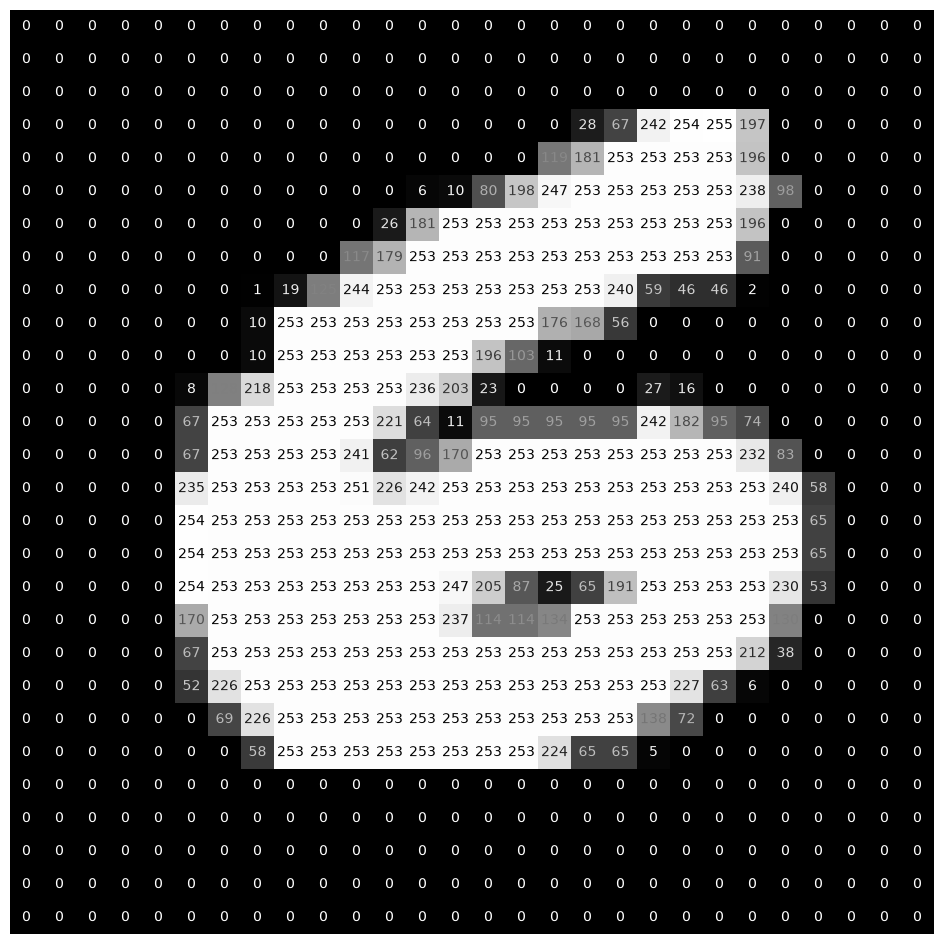

In [63]:
torch.manual_seed(42)

fig = plt.figure(figsize = (12,12)) 
ax0 = fig.add_subplot(1, 1, 1)

rand_ind = torch.randint(0, len(train_dataset), size=[1]).item()

img0 = train_dataset.data[int(rand_ind)]
img0 = img0.numpy()
img_pixel_superimpose(img0, ax0)

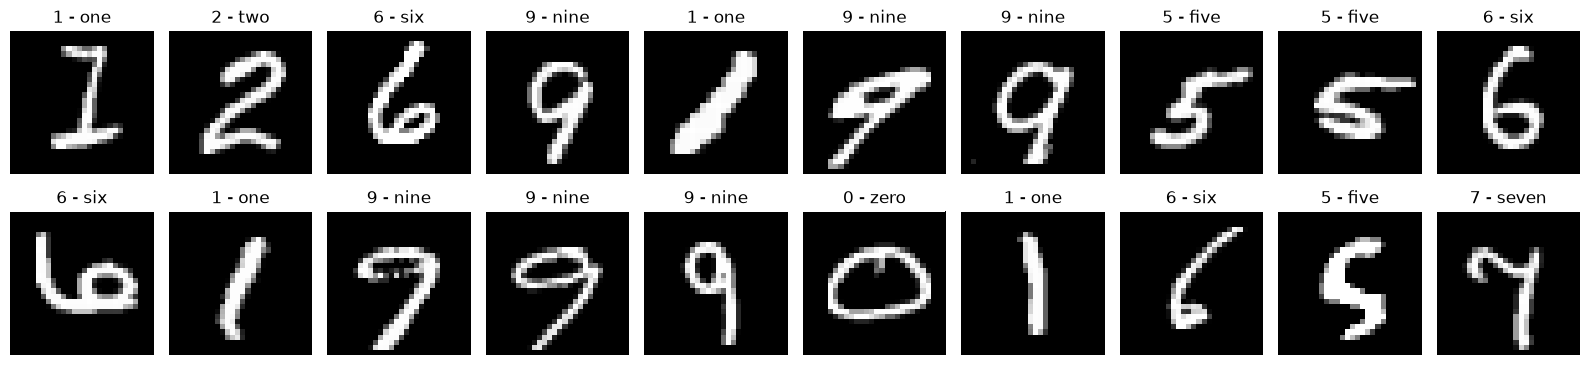

In [57]:
fig = plt.figure(figsize=(16, 4))
rows, cols = 2, 10

for i in range(1, (rows*cols) + 1):
    rand_ind = torch.randint(0, len(train_dataset), size=[1]).item()
    img, label = train_dataset[int(rand_ind)]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img, cmap='gray')
    plt.title(f"{class_names[label]}")
    plt.axis(False)
    plt.tight_layout()

In [64]:
train_dataset = datasets.MNIST(root="./datasets", train=True, download=False, transform=transforms.ToTensor())
test_dataset = datasets.MNIST(root="./datasets", train=False, download=False, transform=transforms.ToTensor())

In [65]:
# Calculating mean and std for normalization

imgs = torch.stack([img for img, _ in train_dataset], dim=0)

mean = imgs.mean()
std = imgs.std()
mean, std

(tensor(0.1307), tensor(0.3081))

In [66]:
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# appplying this transformation to the dataset
train_dataset = datasets.MNIST(root="./datasets", train=True, download=False, transform=mnist_transform)
test_dataset = datasets.MNIST(root="./datasets", train=False, download=False, transform=mnist_transform)
train_dataset, test_dataset

(Dataset MNIST
     Number of datapoints: 60000
     Root location: ./datasets
     Split: Train
     StandardTransform
 Transform: Compose(
                ToTensor()
                Normalize(mean=0.13066047430038452, std=0.30810782313346863)
            ),
 Dataset MNIST
     Number of datapoints: 10000
     Root location: ./datasets
     Split: Test
     StandardTransform
 Transform: Compose(
                ToTensor()
                Normalize(mean=0.13066047430038452, std=0.30810782313346863)
            ))

In [69]:
# splitting the training dataset into train and val sets
train_size = int( 0.85 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_dataset, val_dataset = torch.utils.data.random_split(dataset=train_dataset, lengths=[train_size, val_size])

len(train_dataset), len(val_dataset), len(test_dataset)

(32640, 5760, 10000)

In [70]:
# creating data loaders

from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

len(train_dataloader), len(val_dataloader), len(test_dataloader)

(2040, 360, 625)

In [71]:
32640/16

2040.0

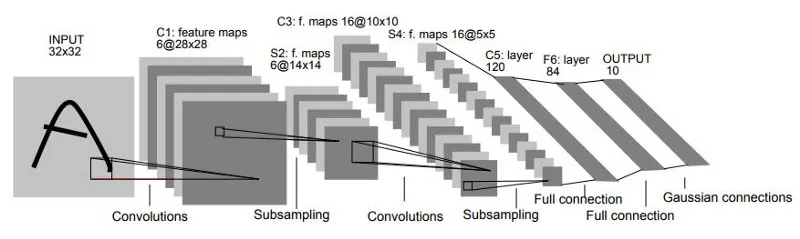

In [72]:
lenet_architecture = Image.open("lenet5.webp")
lenet_architecture

In [74]:
class LeNet5(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.feature = nn.Sequential(
            # first layer ( C1 and S2)
            # dataset contains images of 28x28
            # padded 2 to make 28x28 --> 32x32
            nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1, padding=2),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2), # output size = floor[(n-f)/s] + 1
            # n -> input hxw, f -> kernel size, s -> stride

            # second layer ( C3 and S4)
            nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1), # -> 10x10 (floor(14-5)/1 + 1)
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2), # 5x5 (floor(10-2)/4 + 1)
        )

        # fully connected classifier (C5 and F6)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=16*5*5, out_features=120),
            nn.Tanh(),
            nn.Linear(in_features=120, out_features=84),
            nn.Tanh(),
            nn.Linear(in_features=84, out_features=10),
        )

    #  forward pass
    def forward(self, x):
        return self.classifier(self.feature(x))

In [75]:
# loss function, optimizer and evaluation
from torchmetrics import Accuracy

# initializing the model
model_lenet5 = LeNet5()

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_lenet5.parameters(), lr=0.002)
accuracy = Accuracy(task = "multiclass", num_classes = 10)

In [76]:
device = "cuda" if torch.cuda.is_available() else "cpu"
accuracy = accuracy.to(device)
model_lenet5 = model_lenet5.to(device)

In [ ]:
EPOCHS = 10

for epoch in range(EPOCHS):
    # training loop
    train_loss, train_acc = 0.0, 0.0
    for x, y in train_dataloader:
        x, y = x.to(device), y.to(device)

        model_lenet5.train() # train mode

        y_pred = model_lenet5(x)

        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        acc = accuracy(y_pred, y)
        train_acc += acc

        optimizer.zero_grad()

        loss.backward() # calculate gradient descent

        optimizer.step() # update the parameters according to loss

    train_loss /= len(train_dataloader)
    train_acc /= len(train_dataloader)

    # validation loop
    val_loss, val_acc = 0.0, 0.0
    model_lenet5.eval()
    with torch.inference_mode():
        for x, y in val_dataloader:
            x, y = x.to(device), y.to(device)

            y_pred = model_lenet5(x)

            # calculate loss
            loss = loss_fn(y_pred, y)
            val_loss += loss.item() # add loss value

            # calculate accuracy
            acc = accuracy(y_pred, y)
            val_acc += acc

        val_loss /= len(val_dataloader)
